To run a test of multiple random splits

for seed in [0, 1, 2, ..., 19]:
    split data with seed
    run GA
    evaluate best tree
    store F1

In [ ]:
import sys, os

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

print(" Project root added:", project_root)


 Project root added: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments


In [1]:
import sys
from pathlib import Path

# Get current working directory (notebook-safe)
PROJECT_ROOT = Path.cwd().parents[1]

# Add to Python path if not already there
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root added:", PROJECT_ROOT)


Project root added: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


Gen 1: best F1 = 1.0000
Gen 2: best F1 = 1.0000
Gen 3: best F1 = 1.0000
Gen 4: best F1 = 1.0000
Gen 5: best F1 = 1.0000

 Best gene found:
[7, 1, 8, 2, 4, 0, 5, 7]

 Evaluation Metrics:
f1: 1.0000
recall: 1.0000
specificity: 1.0000
n_nodes: 5.0000

 Best F1 Score from GA: 1.0000


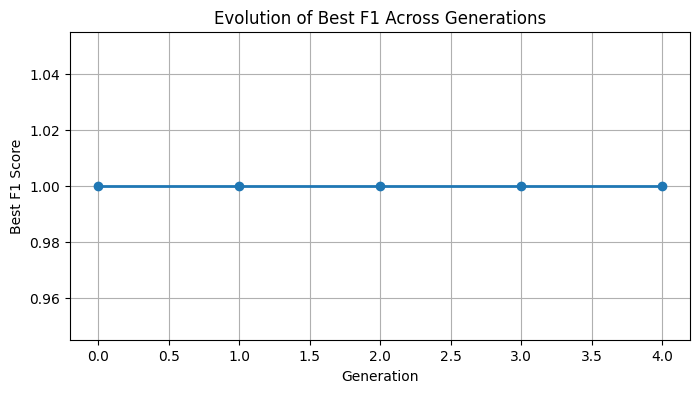

In [ ]:

#  Genetic Algorithm Test for Decision Tree Evolution

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from evolution.genetic_DT_GA import genetic_DT_GA
from evolution.encode_decode import decode
from core.metrics import evaluate_tree


# Load dataset
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Run the genetic algorithm
best_individual, best_fitness, history = genetic_DT_GA(
    X_train, X_test, y_train, y_test,
    mu=6,            # number of parents
    lambd=12,        # number of offspring
    generations=5,   # generations
    crossover_prob=1.0,
    mutation_prob=0.15
)

# Decode best individual into an actual decision tree
print("\n Best gene found:")
print(best_individual)

best_tree = decode(best_individual)
metrics = evaluate_tree(best_tree, X_train, y_train, X_test, y_test)

print("\n Evaluation Metrics:")
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")

print(f"\n Best F1 Score from GA: {best_fitness:.4f}")

# Plot the evolution of best fitness per generation
plt.figure(figsize=(8, 4))
plt.plot(history, marker="o", linewidth=2)
plt.title("Evolution of Best F1 Across Generations")
plt.xlabel("Generation")
plt.ylabel("Best F1 Score")
plt.grid(True)
plt.show()


# New test for the SDoD o como se diga asi le digo yo

Ahorita: usa folds como “mini-instances” → saca varios scores 𝑜_𝑖 → se calcula SDD sobre esos 𝑜_𝑖

Gen 1: best F1 = 0.9358
Gen 2: best F1 = 0.9358
Gen 3: best F1 = 0.9444
Gen 4: best F1 = 0.9444
Gen 5: best F1 = 0.9444

 Best gene found:
[10, 3, 3, 0, 4, 1, 1, 1]
 Fitness (mean - SDD): 0.9444

 Generalization test (5 unseen folds)
F1 per fold: [0.96658312 0.96658312 0.89974937 1.         0.93265993]
Mean F1: 0.9531151110098479
Std F1: 0.034138786907427096


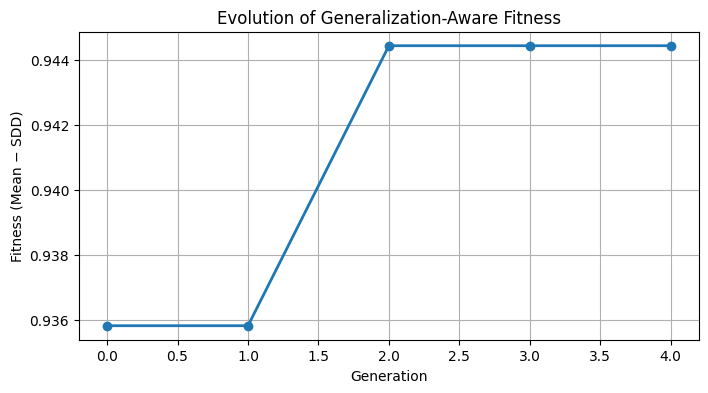

In [2]:
# GA test (Generalization Version)
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold
from evolution.genetic_DT_GA import genetic_DT_GA
from evolution.encode_decode import decode
from core.metrics import evaluate_tree

# Load data
X, y = load_iris(return_X_y=True)

# Run GA
best_individual, best_fitness, history = genetic_DT_GA(
    X, y,                    
    mu=6,
    lambd=12,
    generations=5,
    crossover_prob=1.0,
    mutation_prob=0.15
)

print("\n Best gene found:")
print(best_individual)
print(f" Fitness (mean - SDD): {best_fitness:.4f}")

# Evaluate best individual on NEW folds
best_tree = decode(best_individual)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

scores = []

for train_idx, test_idx in skf.split(X, y):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    metrics = evaluate_tree(best_tree, X_train, y_train, X_test, y_test)
    scores.append(metrics["f1"])

scores = np.array(scores)

print("\n Generalization test (5 unseen folds)")
print("F1 per fold:", scores)
print("Mean F1:", scores.mean())
print("Std F1:", scores.std())

# Plot evolution of fitness
plt.figure(figsize=(8, 4))
plt.plot(history, marker="o", linewidth=2)
plt.title("Evolution of Generalization-Aware Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD)")
plt.grid(True)
plt.show()

Ahora im gonna try to make the instances be datasets completos (Iris, Wine, Obesity, etc.)  y SDD mida variación entre datasets, no entre folds.